# EDA 01: тестовая выборка легковых ТС с ЦДТ

100 проданных лотов с единственной категорией «Легковой транспорт», по 10 лотов со случайных страниц архива (seed 42). Выводы предварительные.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
from src.eda.load import load_cards
from src.eda import summary, text_patterns, plots

pd.set_option("display.max_colwidth", 200)
df = load_cards()
summary.period_summary(df)

лотов                          100
первая публикация       2022-08-01
последняя публикация    2026-06-26
dtype: object

In [2]:
summary.share_table(df, "year_published").sort_index()

,лотов,доля
year_published,,
2022,10,0.1
2024,30,0.3
2025,30,0.3
2026,30,0.3


## Пропуски

In [3]:
summary.missing_shares(df)

auctionTimeBegin     0.76
lot_regionID         0.53
winnerTime           0.24
lot_decreaseRules    0.24
vin_wmi              0.15
vin_year_code        0.15
winnerPriceOffer     0.13
dtype: float64

## Тип торгов, должник, договор

In [4]:
summary.share_table(df, "tradeTypeDescription")

,лотов,доля
tradeTypeDescription,,
Открытое публичное предложение,76,0.76
Открытый аукцион,24,0.24


In [5]:
summary.share_table(df, "debtType")

,лотов,доля
debtType,,
Nat,99,0.99
Jur,1,0.01


In [6]:
summary.share_table(df, "salesContractType")

,лотов,доля
salesContractType,,
Договор заключен с единственным участником торгов,50,0.5
Договор заключен с победителем торгов,50,0.5


## Цены продажи

In [7]:
df["sale_price"].describe().round(0)

count        100.0
mean      489919.0
std       475998.0
min        10000.0
25%       151441.0
50%       321075.0
75%       711915.0
max      2800000.0
Name: sale_price, dtype: float64

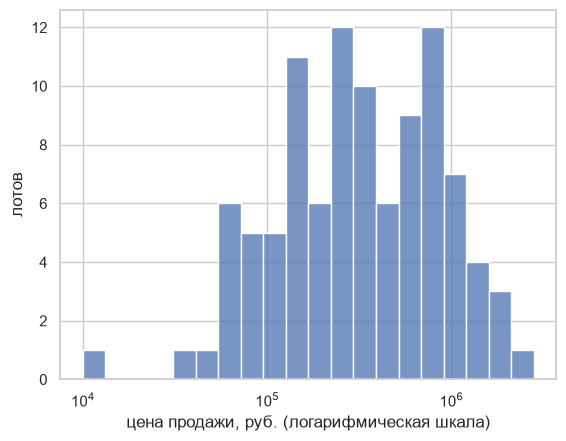

In [8]:
plots.plot_price_distribution(df);

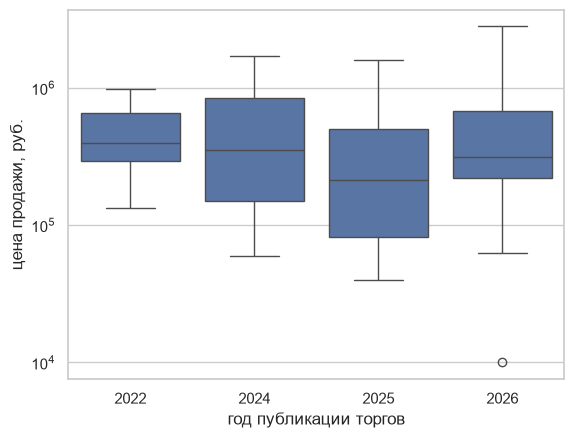

In [9]:
plots.plot_price_by_year(df);

## Цена продажи относительно начальной цены этапа

Для публичного предложения начальная цена этапа уже снижена относительно первых торгов.

In [10]:
df.groupby("tradeTypeDescription")["price_ratio"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
tradeTypeDescription,,,,,,,,
Открытое публичное предложение,76.0,0.69,0.20,0.21,0.52,0.7,0.84,1.09
Открытый аукцион,24.0,1.04,0.08,1.00,1.00,1.0,1.01,1.30


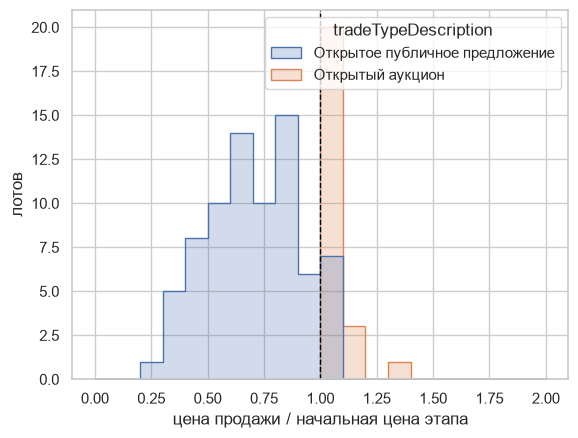

In [11]:
plots.plot_price_ratio(df);

## Что есть в описаниях лотов

In [12]:
text_patterns.pattern_shares(df["lot_info"])

,доля лотов
VIN,0.85
год выпуска,0.77
госномер,0.43
модель указана явно,0.27
залог,0.26
марка указана явно,0.22
мощность,0.18
ДТП / повреждения,0.07
не на ходу / неисправен,0.05
пробег,0.02


In [13]:
text_patterns.multi_vehicle_candidates(df)[["tradeId", "n_vins"]]

,tradeId,n_vins
0,135959,1
17,212567,2


## Выводы

1. Выборка: 100 лотов, опубликованных с августа 2022 по июнь 2026 года. 2020, 2021 и 2023 годы в неё не попали, поэтому доли и распределения ниже предварительные.
2. Должники почти всегда физические лица (99 из 100), это совпадает с практикой пилотного пользователя.
3. На публичном предложении продано 76% лотов, на аукционе 24%. На первой выборке из свежих лотов доля публичного предложения была выше, то есть она зависит от периода.
4. Конкуренции мало: половина договоров заключена с единственным участником, в том числе 13 из 24 аукционов. На аукционах в трёх четвертях случаев цена продажи почти равна начальной (не выше 1.01 от неё), на публичном предложении медиана отношения 0.70 к начальной цене этапа.
5. Цены продажи от 10 тыс. до 2,8 млн руб., медиана около 320 тыс. Распределение сильно скошено вправо, поэтому таргет берётся в логарифме. На 10-30 лотах в год тренд цен по годам оценить нельзя.
6. Год выпуска извлекается регулярным выражением из 77% описаний, вместе с годом из VIN покрытие 97%. VIN есть в 85% описаний, мощность в 18%, пробег в 2%, поэтому пробег как признак почти бесполезен. Основные признаки из текста: марка, модель, год, флаги состояния. Залог упоминается в 26% лотов, повреждения в 7%, неисправность в 5%.
7. Регион в карточке отсутствует у 53% лотов, чаще у старых, его нужно восстанавливать по тексту или адресу.
8. Лотов с несколькими автомобилями не найдено: оба кандидата оказались ложными срабатываниями эвристики (номер кузова распознан как второй VIN, слово «автомобили» в типе ТС).